# Notebook 1 — 终点梯度误差如何损害有限预算 AM

**目标**：在固定真实控制目标下，验证“终点代价值可以很准确，但梯度标签误差仍可能经 adjoint 传播，损害中间学习信号与有限训练的真实性能”。

本 notebook 包括两个可解析实验，代码、公式、数值核验均在下面展开：

- **A：一维严格存在性结果**。对同一批轨迹做一次 AM–SGD 更新，计算真实代价增量的精确期望；不是普遍收敛定理。
- **B：保留此前的三维线性 Gaussian 实验**。检查逐路径误差、条件均值、实际有限样本 AM 回归、状态反馈控制、同 KL 评价、梯度修复与值偏移对照。
- **必须保留的边界**：高频梯度误差可能被条件平均消除；若对近似代价精确求全局最优，统一值误差会限制真实性能差距。因此“大梯度误差必然导致差控制”不成立。

这里允许人为构造解析 critic，用于机制隔离。第二份 notebook 使用自然观测数据拟合 critic，不添加人为梯度扰动。A 使用 SGD 以得到闭式结果；B 解冻结轨迹的回归问题；第二份才是多轮 on-policy lean AM + Adam，不能混称同一种训练实验。

**运行**：在已安装本项目 notebook 依赖的 Python 环境中 Run All，或执行同名 `.py`。所有产物写入新的 `runs/01-motivation-*`，不会覆盖历史实验。

## 共享机制公式：误差在哪里变成有害的更新？

固定
\[
dX_t=[b(X_t,t)+\Sigma u_\theta(X_t,t)]dt+\Sigma\,dW_t,\qquad
J(u)=\mathbb E[\int_0^T(\tfrac12\|u_t\|^2+\ell(X_t,t))dt+g(X_T)].
\]
在冻结采样路径上，lean adjoint 使用
\[
\dot a_t=-D_xb(X_t,t)^\top a_t-\nabla_x\ell(X_t,t),\quad a_T=\nabla g(X_T),
\quad L_{\rm AM}=\tfrac12\mathbb E\int_0^T\|u_\theta+\Sigma^\top a_t\|^2dt.
\]
令终点标签误差 \(e_T=\nabla\hat g(X_T)-\nabla g(X_T)\)，且 \(P_{T,t}\) 是冻结路径上基准漂移的线性化传播矩阵，则
\[
\delta a_t=P_{T,t}^\top e_T,\qquad
\delta y_t=-\Sigma^\top P_{T,t}^\top e_T,\qquad
\delta q=\mathbb E\int_0^T(D_\theta u_\theta)^\top\Sigma^\top P_{T,t}^\top e_T\,dt .
\]
\(y_t=-\Sigma^\top a_t\) 是监督标签，\(q=\nabla_\theta L_{\rm AM}\) 是**冻结标签**后的参数梯度。
所以真正相关的是误差经动力学、控制通道及 actor Jacobian 的投影，不是仅看 \(\|e_T\|\)。
总体回归还涉及 \(\mathbb E[\delta y_t\mid X_t]\)，有限数据会留下残差。
**lean AM 梯度一般不等于真实 \(J\) 的梯度**；下面用真实目标直接核验性能，不靠这一错误等同。

框架出处：[Adjoint Matching, §5.2](https://arxiv.org/html/2409.08861)。
以下解析命题和数值试验是本项目的机制验证，不是该论文声称的定理。

In [1]:
import sys, json, time, platform, hashlib, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize
from scipy.special import iv, ivp
from scipy.stats import t as student_t
import matplotlib
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

torch.set_num_threads(1)
START = time.time()
RUNS = Path.cwd() / 'runs'
RUNS.mkdir(exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix='01-motivation-', dir=RUNS))
CFG = dict(
    A=[0., 1.3, -1.2], T=1., value_error_bound=.01, KL=.2,
    frequencies=[1., 4., 16., 64., 200.],
    sample_sizes=[16, 64, 256, 1024, 4096],
    train_seeds=list(range(103001, 103065)),
    value_test_seed=203001, value_test_paths=200000,
    conditional_test_seed=203002, conditional_test_paths=200000,
    feedback_frequencies=[4., 200.], feedback_sample_sizes=[64, 1024],
    feedback_steps=64, feedback_seed_offset=300000,
    rollout_seeds=[503001, 503002, 503003, 503004, 503005], rollout_paths=8192,
    rollout_training_seed=103001, bessel_terms=24,
)
A = np.array(CFG['A']); T=CFG['T']; EPS=CFG['value_error_bound']; KL=CFG['KL']
G = np.array([1., 0., 0.]); BETA0=np.sqrt(2*KL); J0=BETA0
CHECKS=[]
VERSIONS=dict(python=sys.version,platform=platform.platform(),numpy=np.__version__,
              scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__,torch=torch.__version__)

def check(name, condition, detail=''):
    CHECKS.append(dict(name=name,passed=bool(condition),detail=str(detail)))
    assert condition, f'{name}: {detail}'

def savefig(fig,name):
    fig.savefig(OUT/f'{name}.png',dpi=170,bbox_inches='tight')
    plt.show(); plt.close(fig)

def v(h,a=1.3):
    h=np.asarray(h,dtype=float)
    return h if abs(a)<1e-14 else np.expm1(2*a*h)/(2*a)

W=np.array([v(T,a) for a in A]); V=W[1]
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.grid':True,'grid.alpha':.22,
                     'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_columns',None)
config_text=json.dumps(CFG,sort_keys=True,indent=2)
CONFIG_SHA=hashlib.sha256(config_text.encode()).hexdigest()
(OUT/'config.json').write_text(config_text)
display(pd.Series(VERSIONS,name='Execution environment').to_frame())
display(pd.Series(CFG,name='Fixed before execution').to_frame())
print('Config SHA256:',CONFIG_SHA)
print('Seeds are independent training datasets, NOT independently fitted critics.')

,Execution environment
python,"3.13.11 | packaged by Anaconda, Inc. | (main, ..."
platform,macOS-26.2-arm64-arm-64bit-Mach-O
numpy,2.3.5
scipy,1.16.3
pandas,2.3.3
matplotlib,3.10.8
torch,2.9.1


,Fixed before execution
A,"[0.0, 1.3, -1.2]"
T,1.0
value_error_bound,0.01
KL,0.2
frequencies,"[1.0, 4.0, 16.0, 64.0, 200.0]"
sample_sizes,"[16, 64, 256, 1024, 4096]"
train_seeds,"[103001, 103002, 103003, 103004, 103005, 10300..."
value_test_seed,203001
value_test_paths,200000
conditional_test_seed,203002


Config SHA256: e5f5646b3ef14e986661644629fec3054d3de5c6c83d7f24310b14aa9fa56971
Seeds are independent training datasets, NOT independently fitted critics.


## A. 一次有限批量 AM 更新：严格的期望代价损害

限定为**常数控制策略类** \(u_\theta(t,x)=\theta\)，
\(dX_t=\theta\,dt+dW_t,\ X_0=0,\ T=1,\ g(x)=x^2/2\)。
真实目标
\[
J(\theta)=\mathbb E[\theta^2/2+X_1^2/2]=\theta^2+\tfrac12
\]
在该策略类中于 \(\theta=0\) 最优（不是所有状态反馈策略的最优）。

取可微标量估计
\[
\hat g_\epsilon(x)=g(x)+\epsilon\sin(x/\epsilon^2).
\]
全局值误差至多 \(\epsilon\)，但
\(e_\epsilon(x)=\epsilon^{-1}\cos(x/\epsilon^2)\)。
在 \(\theta_0=0\) 采样 \(W_i\sim N(0,1)\)，lean adjoint 对时间恒定：
\(a_t^{\rm clean}=W_i,\ \hat a_t=W_i+e_\epsilon(W_i)\)。
冻结路径与标签，做一步学习率 \(\eta\) 的 AM–SGD：
\[
\theta_{\rm clean}=-\eta\bar W,\quad
\theta_{\rm noisy}=-\eta(\bar W+\bar e_\epsilon).
\]
由于奇偶对称性 \(\mathbb E[\bar W\bar e_\epsilon]=0\)，
\[
\boxed{\mathbb E[J(\theta_{\rm noisy})-J(\theta_{\rm clean})]
=\frac{\eta^2}{\epsilon^2}
 \left[\frac{(1-z)^2}{2B}+z\right],\qquad z=e^{-1/\epsilon^4}.}
\]
推导：\(\mathbb E\cos(W/\epsilon^2)=\sqrt z\)，
\(\mathbb E\cos^2(W/\epsilon^2)=(1+z^2)/2\)，
故 \(\mathrm{Var}(\cos)=(1-z)^2/2\)，再用独立样本均值的方差除以 \(B\)。

固定有限 \(B,\eta>0\)，当 \(\epsilon\to0\)，损害约为
\(\eta^2/(2B\epsilon^2)\)，尽管值误差趋于零。
这证明“可能损害”的**存在性**，不是每次随机更新必然变差、Adam 的结论、或充分优化后仍会变差。
\(\hat g\) 的精确全局优化与有限样本梯度训练必须区分。

,epsilon,value_error_bound,gradient_RMSE,exact_expected_cost_damage,measured_damage,MC_standard_error
0,0.50,0.50,1.414214,0.000013,0.000012,1.750084e-07
1,0.25,0.25,2.828427,0.000050,0.000050,5.669977e-07
2,0.10,0.10,7.071068,0.000312,0.000314,3.185235e-06
3,0.05,0.05,14.142136,0.001250,0.001280,1.259183e-05


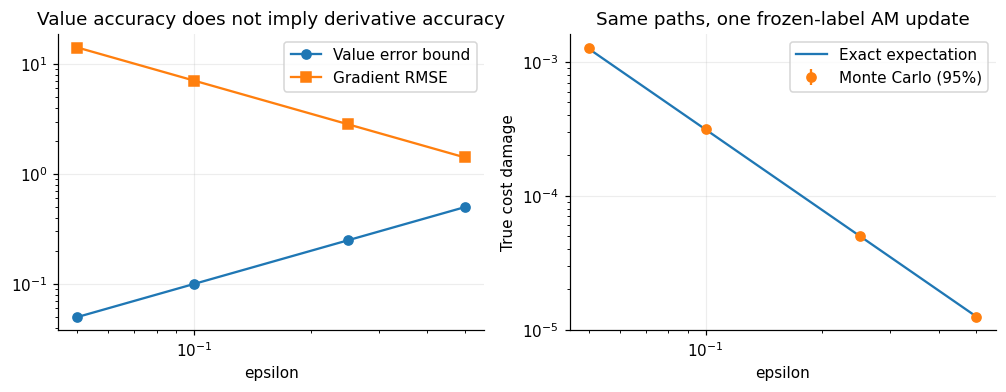

836

In [2]:
# A: common-random-number Monte Carlo plus an actual autograd AM step.
import math
_A_RNG = np.random.default_rng(17031)
_A_B, _A_ETA, _A_REPS = 64, .02, 20000
_A_W = _A_RNG.normal(size=(_A_REPS, _A_B))
_A_CLEAN = -_A_ETA * _A_W.mean(1)
A_ROWS = []
for epsilon in (.5, .25, .1, .05):
    error = np.cos(_A_W / epsilon**2) / epsilon
    noisy = _A_CLEAN - _A_ETA * error.mean(1)
    measured = noisy**2 - _A_CLEAN**2
    z = math.exp(-1 / epsilon**4)
    theory = _A_ETA**2 / epsilon**2 * ((1-z)**2 / (2*_A_B) + z)
    se = measured.std(ddof=1) / math.sqrt(_A_REPS)
    check(f'A expectation epsilon={epsilon}', abs(measured.mean()-theory) < 5*se+1e-7)
    # Derive the labels from a scalar cost, not from a manually corrupted vector.
    w = torch.tensor(_A_W[0], dtype=torch.float64, requires_grad=True)
    ghat = .5*w.square() + epsilon*torch.sin(w / epsilon**2)
    labels = torch.autograd.grad(ghat.sum(), w)[0].detach()
    theta = torch.tensor(0., dtype=torch.float64, requires_grad=True)
    loss = .5*(theta + labels).square().mean()
    actual = -_A_ETA*torch.autograd.grad(loss, theta)[0].item()
    check(f'A actual AM-SGD step epsilon={epsilon}', abs(actual-noisy[0]) < 1e-12)
    A_ROWS.append(dict(epsilon=epsilon, value_error_bound=epsilon,
                       gradient_RMSE=math.sqrt((1+z*z)/(2*epsilon**2)),
                       exact_expected_cost_damage=theory, measured_damage=measured.mean(),
                       MC_standard_error=se))
A_TABLE = pd.DataFrame(A_ROWS)
display(A_TABLE)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].loglog(A_TABLE.epsilon, A_TABLE.value_error_bound, 'o-', label='Value error bound')
axes[0].loglog(A_TABLE.epsilon, A_TABLE.gradient_RMSE, 's-', label='Gradient RMSE')
axes[0].set(xlabel='epsilon', title='Value accuracy does not imply derivative accuracy')
axes[0].legend()
axes[1].loglog(A_TABLE.epsilon, A_TABLE.exact_expected_cost_damage, '-', label='Exact expectation')
axes[1].errorbar(A_TABLE.epsilon, A_TABLE.measured_damage,
                 yerr=1.96*A_TABLE.MC_standard_error, fmt='o', label='Monte Carlo (95%)')
axes[1].set(yscale='log', xscale='log', xlabel='epsilon', ylabel='True cost damage',
            title='Same paths, one frozen-label AM update')
axes[1].legend()
savefig(fig, '00_scalar_AM_update')
plt.show()
(OUT/'scalar_one_step.json').write_text(A_TABLE.to_json(orient='records', indent=2))

## 实验 B：线性 Gaussian 系统中的中间信用信号与控制

**与 A 的区别**：B 沿用此前的 reward 记号和同 path-KL 预算比较：最大化真实
$\mathbb E[Q(X_T)]$，约束 $\frac12\mathbb E\int\|u_t\|^2dt=0.2$。
对应惩罚形式的终点代价是 $g=-\beta Q$，所以监督方向由“负代价梯度”变为“正奖励梯度”。
A 和 B 是两个各自固定真实目标的实验，不是在一个训练过程中把目标换掉。
B 的 KL 校准与冻结轨迹回归也不是 A 的一步 SGD，或第二份 notebook 的多轮 Adam。

### B.0 这次究竟验证什么？

**用户的 motivation**：Q 的数值可以已经很接近，但终点梯度仍然不可靠；
这种误差可能污染 AM 在中间生成时刻的信用分配/匹配目标，进而损害控制效果。
这里的时间是**动作生成/去噪时间**，不是 RL 环境中的不同决策步。

本 notebook 是实际可运行的受控机制实验，不是新 uncertainty 方法，也不是 TRQAM benchmark。
在下面这项保留的早期实验中，同时检查：

1. Q **值**确实接近，而**梯度**不接近。
2. 逐轨迹 Lean Adjoint 误差，以及给定当前状态后平均的**有效回归目标误差**。
3. 从采样轨迹真正拟合的、部署时不偷看终点的 AM 控制；同 KL 下评估真实 Q。
4. 保持 Q 数值不变、只修复终点梯度的因果干预；只有值偏移、梯度正确的负对照。
5. 有限样本 AM 更新与精确优化的区别。若精确最优策略几乎不受影响，必须报告这个反例。

**范围**：构造可微 scalar critic，而非直接伪造一个不保守梯度场。
计算一轮冻结参考轨迹的 AM 回归子问题，使用精确最小二乘消除 SGD/网络收敛混杂；
既有时间依赖控制，也有依赖中间状态的反馈控制。**不是多轮 on-policy AM 的收敛实验**，
没有训练真实 critic，不能宣称真实 TRQAM 中已经观察到同样的故障。
原实验及其历史输出未被覆盖。

所有频率、样本数、独立训练样本 seeds 和评价规则在运行前写入配置；不选最好/最坏 seed。
正结果、零结果、反例一起展示。数值断言只检查实现，不把“支持假设”写成必须通过的断言。

### B.1. 与 AM 的精确对应，以及不能跳过的条件平均

固定初值 $X_0=0$，基准 SDE 和控制 SDE 分别为
$$dX_t=AX_tdt+dW_t,\qquad dX_t=(AX_t+u_t)dt+dW_t,$$
其中 $A=\operatorname{diag}(0,1.3,-1.2)$，$T=1$。
采用正奖励梯度约定 $p=-\tilde a/\beta$，则 Lean Adjoint 和匹配目标为
$$\dot p_t=-A^\top p_t,\quad p_T=\nabla Q(X_T),\quad
Y_t=\beta p_t=\beta H_t\nabla Q(X_T),\quad H_t=e^{A^\top(1-t)}.$$
对同一批冻结轨迹，AM 子问题是
$$\mathcal L_Q(u)=\tfrac12\mathbb E_{P^0}\int_0^1\|u(X_t,t)-Y_t\|^2dt.$$
轨迹和目标都 stop-gradient。
$$\Delta Y_t=\beta H_t(\nabla\widehat Q(X_T)-\nabla Q(X_T)).$$
而固定轨迹下参数梯度的变化是
$$\Delta\nabla_\theta\mathcal L=-\mathbb E\int
(J_\theta u_\theta)^\top\Delta Y_tdt.$$
因此误差是否投影到可学习方向也重要。

**关键区别**：无限容量回归的目标是
$$u_{\rm regression}(x,t)=\mathbb E[Y_t\mid X_t=x],$$
不是事后拿到 $X_T$ 再把 $Y_t(X_T)$ 当作可部署控制。
平方误差分解为“对条件均值的拟合误差 + 条件方差”；大逐轨迹误差可以被平均掉。

这里把 $Y_t$ 称为**中间 AM 监督/操作性信用信号**，不把 Lean Adjoint 冒充任意当前策略下
真实回报的精确状态导数。原 AM 的 Lean Adjoint 去掉了控制 Jacobian 等项；
这里的线性基漂移、加性噪声给出其可解析特例。
方程对应 [AM §5.2](https://arxiv.org/html/2409.08861#S5.SS2)
和 [QAM §4](https://arxiv.org/html/2601.14234v1#S4)，其余推导和实验为本 notebook 的受控构造。

### B.2. 值几乎相同，梯度很不同：真正可微的 critic

设
$$Q(x)=x_1,\qquad \widehat Q_k(x)=x_1+\epsilon\sin(kx_2),\qquad\epsilon=.01.$$
对**所有状态**都有 $|\widehat Q_k-Q|\le.01$，不是只在训练点上接近。
$$\delta g_k(x)=\epsilon k\cos(kx_2)e_2.$$
在参考终点分布 $X_{T,2}\sim N(0,V)$ 下，
$$\mathrm{RMSE}_Q^2=\tfrac{\epsilon^2}{2}(1-e^{-2k^2V}),\qquad
\mathrm{RMSE}_g^2=\tfrac{\epsilon^2 k^2}{2}(1+e^{-2k^2V}).$$
真实梯度范数为 1，故这里的梯度 RMSE 也可直接作为相对于真实梯度的比例。
此外加入 $Q_{\rm shift}=Q+\mathrm{RMSE}_Q$：在参考分布上具有完全相同 Q RMSE，但梯度完全正确。
高频例子不是对实际 critic 的频谱断言；它是严格分离 value accuracy 与 gradient accuracy 的干预。

,k,Q_uniform_bound,Q_RMSE_theory,Q_RMSE_MC,grad_RMSE_theory,grad_RMSE_MC,Q_shift_RMSE,Q_shift_grad_error
0,1.0,0.01,0.007071,0.007067,0.007071,0.007075,0.007071,0.0
1,4.0,0.01,0.007071,0.007071,0.028284,0.028284,0.007071,0.0
2,16.0,0.01,0.007071,0.007068,0.113137,0.113191,0.007071,0.0
3,64.0,0.01,0.007071,0.007069,0.452548,0.452704,0.007071,0.0
4,200.0,0.01,0.007071,0.007065,1.414214,1.415362,0.007071,0.0


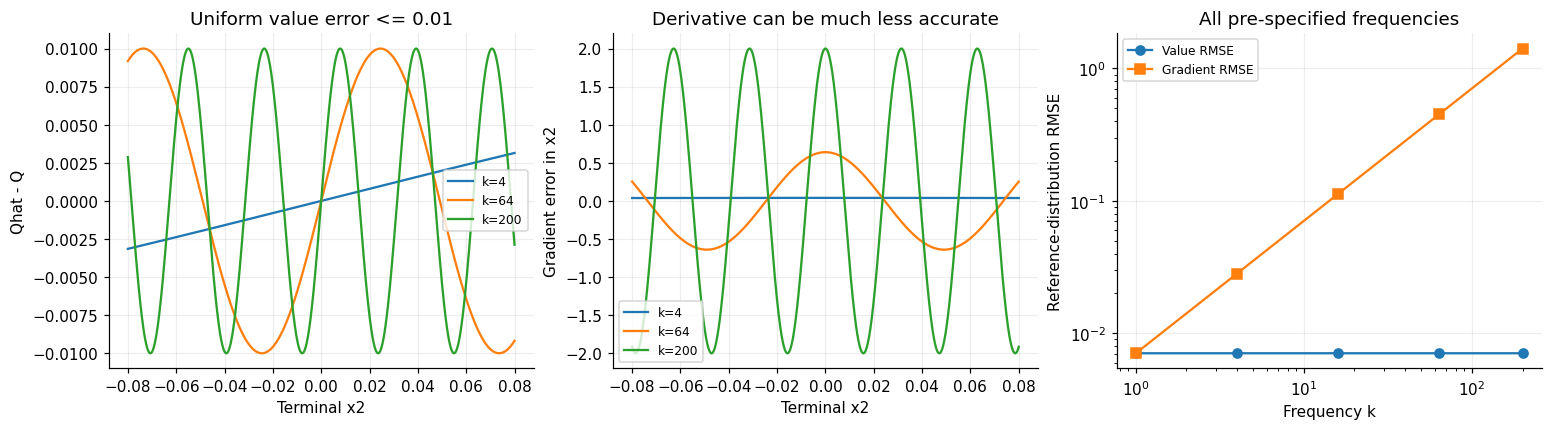

In [3]:
def dq(x,k): return EPS*np.sin(k*np.asarray(x))
def dg(x,k): return EPS*k*np.cos(k*np.asarray(x))
def q_mse(k): return EPS**2/2*(-np.expm1(-2*k*k*V))
def g_mse(k): return EPS**2*k*k/2*(1+np.exp(-2*k*k*V))
def mean_g(k): return EPS*k*np.exp(-.5*k*k*V)

xt=np.random.default_rng(CFG['value_test_seed']).normal(0,np.sqrt(V),CFG['value_test_paths'])
value_rows=[]
for k in CFG['frequencies']:
    qerr=dq(xt,k); gerr=dg(xt,k)
    value_rows.append(dict(k=k,Q_uniform_bound=EPS,Q_RMSE_theory=np.sqrt(q_mse(k)),
        Q_RMSE_MC=np.sqrt(np.mean(qerr**2)),grad_RMSE_theory=np.sqrt(g_mse(k)),
        grad_RMSE_MC=np.sqrt(np.mean(gerr**2)),Q_shift_RMSE=np.sqrt(q_mse(k)),Q_shift_grad_error=0.))
    check(f'value bound k={k}',np.max(np.abs(qerr))<=EPS)
    for label,data,truth in [('Q MSE',qerr**2,q_mse(k)),('gradient MSE',gerr**2,g_mse(k))]:
        se=np.std(data,ddof=1)/np.sqrt(len(data))
        check(f'MC {label} k={k}',abs(np.mean(data)-truth)<6*se+1e-12)
    xx=torch.tensor([[.2,-.007,.4],[-.3,.011,.9]],dtype=torch.float64,requires_grad=True)
    qhat=xx[:,0]+EPS*torch.sin(k*xx[:,1])
    automatic=torch.autograd.grad(qhat.sum(),xx)[0].detach().numpy()
    expected=np.column_stack([np.ones(2),dg(xx.detach().numpy()[:,1],k),np.zeros(2)])
    check(f'gradient is scalar Q autograd k={k}',np.max(np.abs(automatic-expected))<1e-12)
VALUE=pd.DataFrame(value_rows)
display(VALUE)
fig,axes=plt.subplots(1,3,figsize=(14,3.8),constrained_layout=True)
x=np.linspace(-.08,.08,2001)
for k in [4.,64.,200.]:
    axes[0].plot(x,dq(x,k),label=f'k={k:g}')
    axes[1].plot(x,dg(x,k),label=f'k={k:g}')
axes[0].set(xlabel='Terminal x2',ylabel='Qhat - Q',title='Uniform value error <= 0.01')
axes[1].set(xlabel='Terminal x2',ylabel='Gradient error in x2',title='Derivative can be much less accurate')
axes[2].loglog(VALUE.k,VALUE.Q_RMSE_theory,'o-',label='Value RMSE')
axes[2].loglog(VALUE.k,VALUE.grad_RMSE_theory,'s-',label='Gradient RMSE')
axes[2].set(xlabel='Frequency k',ylabel='Reference-distribution RMSE',title='All pre-specified frequencies')
for ax in axes: ax.legend(fontsize=8)
savefig(fig,'01_value_vs_gradient')

### B.3. 是否真的传到中间时刻？逐轨迹误差与有效目标分开测量

记 $a=1.3,\ \tau=1-t,\ K=e^{a\tau}$，$v(h)=(e^{2ah}-1)/(2a)$。
同一轨迹上
$$\Delta p_t=K\epsilon k\cos(kX_{T,2})e_2.$$
它会反向传播，并且在本例的第 2 维被放大。
但参考动力学给出
$$X_{T,2}\mid X_{t,2}=x\sim N(Kx,v(\tau)),$$
所以**有效目标的误差**是
$$m_t(x)=\mathbb E[\Delta p_t\mid X_{t,2}=x]
=K\epsilon k\,e^{-k^2v(\tau)/2}\cos(kKx)e_2.$$
对当前状态再平均，得到两个不同的诊断量：
$$E_{\rm path}(t)=K^2\mathrm{RMSE}_g^2,$$
$$E_{\rm effective}(t)=\tfrac{K^2\epsilon^2k^2}{2}
e^{-k^2v(\tau)}[1+e^{-2k^2K^2v(t)}].$$
上述量是正奖励 adjoint 的误差；乘以 $\beta_0^2$ 才是匹配目标 $Y$ 的误差能量。
条件方差部分为 $E_{\rm path}-E_{\rm effective}$。高频误差的有效影响可能集中在极靠近终点的窄层，
不能把逐轨迹向后放大直接解释成早期策略的系统性偏差。

本例还满足一个独立校验恒等式（可直接积分，也可用条件期望鞅的 Itô 等距）：
$$\int_0^1 E_{\rm effective}(t)dt
=\operatorname{Var}_{P^0}[\widehat Q_k(X_T)-Q(X_T)]
=\tfrac{\epsilon^2}{2}(1-e^{-2k^2V}).$$
所以在这个固定参考扩散下，**理想条件平均的误差信号能量受 value error 控制**；
原始梯度 RMSE 随频率增长，不意味着该有效能量也增长。

,k,pathwise_integrated_adjoint_error,effective_integrated_adjoint_error,effective_quad_error,effective_integrated_exact,target_noise_energy
0,1.0,0.000240,0.00005,2.368403e-14,0.00005,0.000076
1,4.0,0.003835,0.00005,5.080634e-17,0.00005,0.001514
2,16.0,0.061360,0.00005,4.638174e-15,0.00005,0.024524
3,64.0,0.981759,0.00005,3.311227e-15,0.00005,0.392684
4,200.0,9.587491,0.00005,3.248651e-15,0.00005,3.834976


,k,t,x,conditional_MC,SE,conditional_exact
0,4.0,0.50000,0.200,0.000113,0.000121,7.965418e-07
1,200.0,0.50000,0.200,-0.003655,0.006059,0.000000e+00
2,200.0,0.99999,0.002,1.505632,0.001331,1.508214e+00


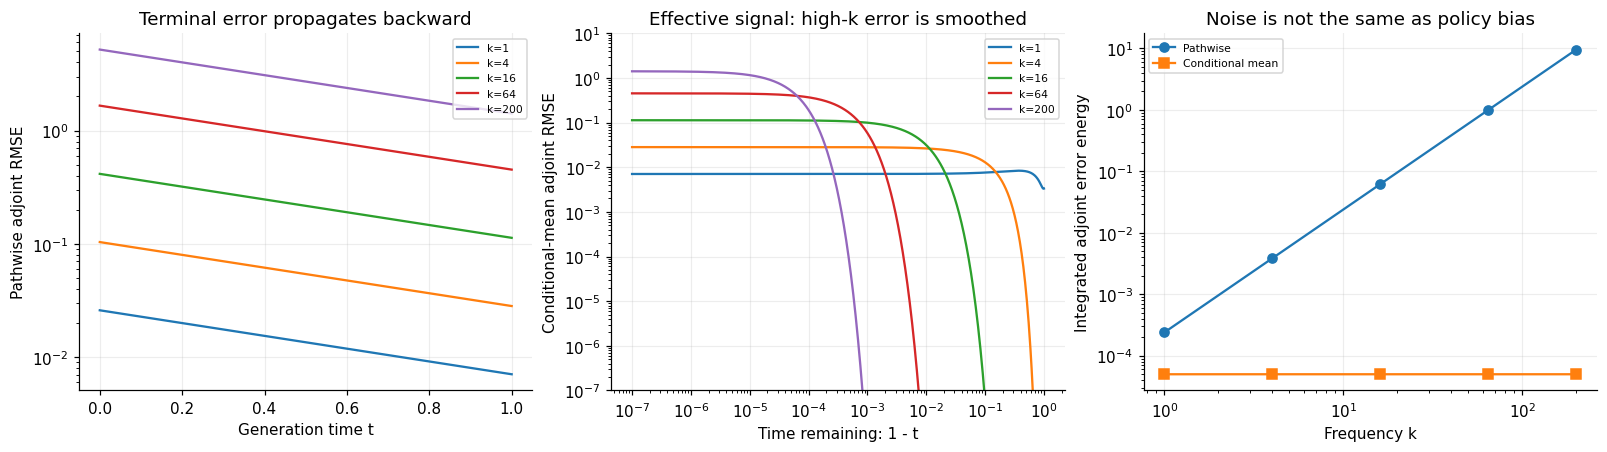

In [4]:
def path_energy(t,k): return np.exp(2*A[1]*(1-np.asarray(t)))*g_mse(k)
def effective_energy(t,k):
    t=np.asarray(t); K=np.exp(A[1]*(1-t))
    return (K*EPS*k)**2/2*np.exp(-k*k*v(1-t))*(1+np.exp(-2*k*k*K*K*v(t)))
def conditional_target(x,t,k):
    K=np.exp(A[1]*(1-t))
    return K*EPS*k*np.exp(-.5*k*k*v(1-t))*np.cos(k*K*x)

prop_rows=[]
for k in CFG['frequencies']:
    # Integrate in time-to-go; resolve the O(k^-2) terminal boundary layer explicitly.
    split=np.unique(np.clip(np.array([0.,.01,.1,1.,10.,100.])/(k*k),0,1))
    integral,err=quad(lambda tau:float(effective_energy(1-tau,k)),0,1,
                      points=split[(split>0)&(split<1)],epsabs=1e-12,epsrel=1e-9,limit=200)
    prop_rows.append(dict(k=k,pathwise_integrated_adjoint_error=V*g_mse(k),
        effective_integrated_adjoint_error=integral,effective_quad_error=err,
        effective_integrated_exact=q_mse(k),
        target_noise_energy=BETA0**2*(V*g_mse(k)-integral)))
    ts=np.unique(np.r_[np.linspace(0,1,301),1-np.logspace(-7,0,501)])
    check(f'conditional expectation contraction k={k}',np.all(effective_energy(ts,k)<=path_energy(ts,k)+1e-12))
    check(f'conditional integral precision k={k}',err<1e-9)
    check(f'independent Ito-isometry integral identity k={k}',abs(integral-q_mse(k))<1e-11)
PROP=pd.DataFrame(prop_rows)
display(PROP)

# Independent backward ODE, plus conditional Gaussian Monte Carlo at pre-specified probe states.
delta=np.array([0.,dg(.003,200.),0.])
ode=solve_ivp(lambda t,p:-A*p,(1.,0.),delta,rtol=1e-11,atol=1e-12,dense_output=True)
ts=np.linspace(0,1,301)
closed=np.exp((1-ts[:,None])*A)*delta
check('backward lean adjoint ODE',np.max(np.abs(ode.sol(ts).T-closed))<1e-8)
crng=np.random.default_rng(CFG['conditional_test_seed']); conditional_rows=[]
for k,t,x in [(4.,.5,.2),(200.,.5,.2),(200.,.99999,.002)]:
    future=np.exp(A[1]*(1-t))*x+np.sqrt(v(1-t))*crng.standard_normal(CFG['conditional_test_paths'])
    target=np.exp(A[1]*(1-t))*dg(future,k)
    mean=target.mean(); se=target.std(ddof=1)/np.sqrt(len(target)); exact=conditional_target(x,t,k)
    conditional_rows.append(dict(k=k,t=t,x=x,conditional_MC=mean,SE=se,conditional_exact=exact))
    check(f'conditional MC k={k} t={t}',abs(mean-exact)<6*se+1e-10)
CONDITIONAL=pd.DataFrame(conditional_rows); display(CONDITIONAL)

fig,axes=plt.subplots(1,3,figsize=(14.5,4),constrained_layout=True)
for k in CFG['frequencies']:
    tt=np.linspace(0,1,501)
    axes[0].semilogy(tt,np.sqrt(path_energy(tt,k)),label=f'k={k:g}')
    tau=np.logspace(-7,0,701)
    axes[1].loglog(tau,np.maximum(np.sqrt(effective_energy(1-tau,k)),1e-14),label=f'k={k:g}')
axes[0].set(xlabel='Generation time t',ylabel='Pathwise adjoint RMSE',title='Terminal error propagates backward')
axes[1].set(xlabel='Time remaining: 1 - t',ylabel='Conditional-mean adjoint RMSE',ylim=(1e-7,10),
            title='Effective signal: high-k error is smoothed')
axes[2].loglog(PROP.k,PROP.pathwise_integrated_adjoint_error,'o-',label='Pathwise')
axes[2].loglog(PROP.k,PROP.effective_integrated_adjoint_error,'s-',label='Conditional mean')
axes[2].set(xlabel='Frequency k',ylabel='Integrated adjoint error energy',title='Noise is not the same as policy bias')
for ax in axes: ax.legend(fontsize=7)
savefig(fig,'02_pathwise_vs_effective_credit')

### B.4. 从数据实际拟合 AM：精确求解有限样本回归子问题

首先使用任意确定性时间函数 $u(t)$。对每个独立训练样本 seed，采样 $N$ 条参考轨迹的终点；
由于这里的 adjoint 只依赖终点及 $t$，终点是时间函数回归的充分数据，无须存整条轨迹。
固定 $\beta_0=\sqrt{.4}$，求解
$$\min_{u:\frac12\int\|u\|^2\le.2}\frac1{2N}\sum_i
\int\|u(t)-\beta_0H_t\nabla\widehat Q_k(X_T^{(i)})\|^2dt.$$
这是一个**实际训练子问题**，不是直接把某个测试终点的梯度输入控制。
其精确 ERM 解为样本均值目标向 KL 球的投影。记
$$\bar\delta_{N,k}=\frac1N\sum_i\epsilon k\cos(kX_{T,2}^{(i)}),$$
则
$$u_{N,k}(t)=cH_t(e_1+\bar\delta_{N,k}e_2),\qquad
c=\sqrt{\frac{.4}{1+V\bar\delta_{N,k}^2}}.$$
**真实收益** $J=c$，实际 path-KL 精确为 $.2$，中间样本均值目标的误差能量是
$\beta_0^2V\bar\delta_{N,k}^2$。
该控制只依赖训练数据和当前时间，部署时不依赖未来随机性。

每个 seed 内所有频率使用同一批终点，不同 $N$ 使用其前缀；每个条件的 64 个 seeds 独立。
表中的置信区间只对**训练数据重复实验均值**计算，不把测试轨迹当作独立训练。
理论上
$$\mathbb E\bar\delta^2=(\mathbb E\delta g)^2+\operatorname{Var}(\delta g)/N.$$
这是有限样本残留噪声通向实际控制偏差的机制；无限样本时它可能消失。

,condition,k,N,mean_return,SD_return,mean_gap,SD_gap,mean_relative_gap,min_return,max_return,replications,mean_gap_CI95_half
45,Noisy gradient,200.0,16,0.536312,0.092198,0.096144,0.092198,0.152016,0.264434,0.632451,64,0.023030
46,Noisy gradient,200.0,64,0.603426,0.031498,0.029030,0.031498,0.045900,0.507811,0.632437,64,0.007868
47,Noisy gradient,200.0,256,0.621331,0.016482,0.011124,0.016482,0.017589,0.558058,0.632419,64,0.004117
48,Noisy gradient,200.0,1024,0.630087,0.003667,0.002368,0.003667,0.003745,0.611337,0.632456,64,0.000916
49,Noisy gradient,200.0,4096,0.631840,0.000826,0.000615,0.000826,0.000972,0.627991,0.632455,64,0.000206


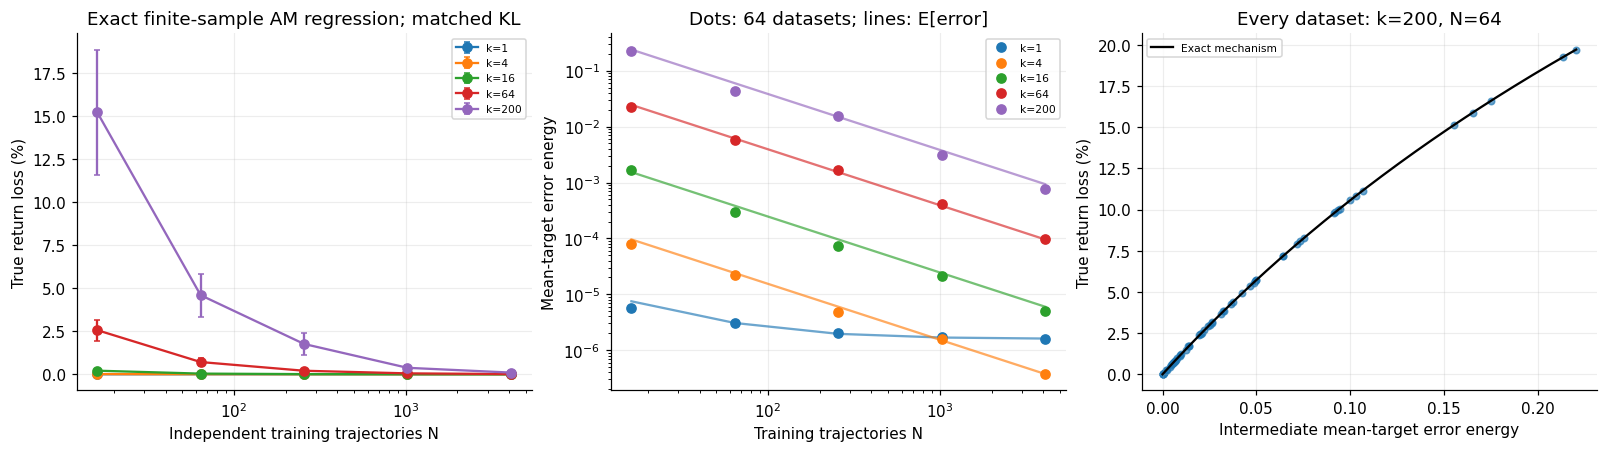

In [5]:
rows=[]
for seed in CFG['train_seeds']:
    terminal=np.random.default_rng(seed).normal(0,np.sqrt(V),max(CFG['sample_sizes']))
    for k in CFG['frequencies']:
        grad=dg(terminal,k)
        for n in CFG['sample_sizes']:
            d=grad[:n].mean(); qerr=dq(terminal[:n],k)
            c=np.sqrt(2*KL/(1+V*d*d))
            for condition,used_d in [('Noisy gradient',d),('Gradient repair',0.),('Value shift',0.),('Oracle',0.)]:
                cc=np.sqrt(2*KL/(1+V*used_d**2))
                rows.append(dict(seed=seed,k=k,N=n,condition=condition,
                    observed_Q_RMSE=float(np.sqrt(np.mean(qerr*qerr))) if condition in ['Noisy gradient','Gradient repair']
                                      else np.sqrt(q_mse(k)) if condition=='Value shift' else 0.,
                    mean_terminal_gradient_error=used_d,
                    intermediate_mean_target_error_energy=BETA0**2*V*used_d**2,
                    true_return=cc,return_gap=J0-cc,relative_gap=(J0-cc)/J0,
                    actual_path_KL=.5*cc**2*(1+V*used_d**2)))
ERM=pd.DataFrame(rows)
check('all time-only policies exactly match KL',np.max(np.abs(ERM.actual_path_KL-KL))<1e-12)
check('repair leaves numerical Q error unchanged',np.array_equal(
    ERM[ERM.condition=='Noisy gradient'].observed_Q_RMSE.to_numpy(),
    ERM[ERM.condition=='Gradient repair'].observed_Q_RMSE.to_numpy()))
check('all repaired and value-only controls equal oracle',np.max(np.abs(ERM[ERM.condition!='Noisy gradient'].return_gap))<1e-12)

def summarize(frame,keys):
    result=frame.groupby(keys,sort=True).agg(mean_return=('true_return','mean'),SD_return=('true_return','std'),
        mean_gap=('return_gap','mean'),SD_gap=('return_gap','std'),mean_relative_gap=('relative_gap','mean'),
        min_return=('true_return','min'),max_return=('true_return','max'),replications=('seed','size')).reset_index()
    result['mean_gap_CI95_half']=student_t.ppf(.975,result.replications-1)*result.SD_gap/np.sqrt(result.replications)
    return result

ERM_SUM=summarize(ERM,['condition','k','N'])
display(ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.k==200.)])

# Independent numerical optimizer of the finite-dimensional equivalent, not the closed formula.
probe=ERM[(ERM.seed==CFG['train_seeds'][0])&(ERM.k==200.)&(ERM.N==64)&(ERM.condition=='Noisy gradient')].iloc[0]
target=BETA0*np.array([1.,probe.mean_terminal_gradient_error,0.])
sol=minimize(lambda z:.5*np.sum(W*(z-target)**2),np.array([.5,0.,0.]),
    jac=lambda z:W*(z-target),method='SLSQP',
    constraints=[dict(type='ineq',fun=lambda z:2*KL-np.sum(W*z*z),jac=lambda z:-2*W*z)],
    options=dict(ftol=1e-13,maxiter=200))
expected=probe.true_return*np.array([1.,probe.mean_terminal_gradient_error,0.])
check('independent constrained ERM optimizer',sol.success and np.linalg.norm(sol.x-expected)<1e-6,str(sol.message))

# Recover the full gradient of the frozen matching loss using autograd.
tt=torch.linspace(0,1,501,dtype=torch.float64)
hh=torch.exp((1-tt[:,None])*torch.tensor(A,dtype=torch.float64))
param=torch.zeros(3,dtype=torch.float64,requires_grad=True)
target_o=BETA0*hh*torch.tensor(G,dtype=torch.float64)
target_h=BETA0*hh*torch.tensor([1.,probe.mean_terminal_gradient_error,0.],dtype=torch.float64)
lo=.5*torch.trapezoid(((hh*param-target_o)**2).sum(1),tt)
lh=.5*torch.trapezoid(((hh*param-target_h)**2).sum(1),tt)
go=torch.autograd.grad(lo,param)[0]; gh=torch.autograd.grad(lh,param)[0]
prediction=-torch.trapezoid(hh*(target_h-target_o),tt,dim=0)
check('AM parameter-gradient shift identity',torch.max(torch.abs((gh-go)-prediction)).item()<1e-12)

fig,axes=plt.subplots(1,3,figsize=(14.5,4),constrained_layout=True)
for k in CFG['frequencies']:
    sub=ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.k==k)]
    axes[0].errorbar(sub.N,100*sub.mean_relative_gap,yerr=100*sub.mean_gap_CI95_half/J0,marker='o',label=f'k={k:g}',capsize=2)
    emp=ERM[(ERM.condition=='Noisy gradient')&(ERM.k==k)].groupby('N').intermediate_mean_target_error_energy.mean()
    nn=np.array(CFG['sample_sizes']); theoretical=BETA0**2*V*(mean_g(k)**2+(g_mse(k)-mean_g(k)**2)/nn)
    points=axes[1].loglog(emp.index,emp.values,'o',label=f'k={k:g}')[0]
    axes[1].loglog(nn,theoretical,alpha=.65,color=points.get_color())
sub=ERM[(ERM.condition=='Noisy gradient')&(ERM.k==200.)&(ERM.N==64)]
axes[2].scatter(sub.intermediate_mean_target_error_energy,100*sub.relative_gap,s=18,alpha=.65)
ee=np.linspace(0,sub.intermediate_mean_target_error_energy.max(),201)
axes[2].plot(ee,100*(1-1/np.sqrt(1+ee/BETA0**2)),color='black',label='Exact mechanism')
axes[0].set(xscale='log',xlabel='Independent training trajectories N',ylabel='True return loss (%)',
            title='Exact finite-sample AM regression; matched KL')
axes[1].set(xlabel='Training trajectories N',ylabel='Mean-target error energy',title='Dots: 64 datasets; lines: E[error]')
axes[2].set(xlabel='Intermediate mean-target error energy',ylabel='True return loss (%)',
            title='Every dataset: k=200, N=64')
for ax in axes: ax.legend(fontsize=7)
savefig(fig,'03_finite_sample_AM_control')

### B.5. 不只做开环：用中间状态实际训练反馈控制

进一步从完整参考轨迹回归 $Y_t$，不只使用终点样本均值。
策略类为 64 个时间区间上的状态反馈：
$$u_1=\alpha\beta_0,\quad u_2=\alpha(a_j+b_jX_{t_j,2}),\quad u_3=0,$$
区间内控制保持不变（sample-and-hold），下一区间重新观察当前状态。
每个 $j$ 上用所有训练轨迹的 $(X_{t_j,2},Y_{t_j,2})$ **精确最小二乘**拟合 $(a_j,b_j)$。
第一维的常数目标由同一回归精确拟合为 $\beta_0$；第三维为 0。
初始状态为常数，所以 $t=0$ 只拟合截距。这是事先固定的仿射策略类，不选择网络结构来制造结果。

先按冻结参考分布拟合，再对全控制施加正的全局尺度 $\alpha$，在**实际受控分布**上匹配 KL。
这不是声称全局最优地解了状态反馈约束回归，也不是 on-policy 策略迭代。
由于 sample-and-hold 控制对过去可测，部署时不使用 $X_T$。

令 $F=e^{a\Delta},\ B_\Delta=(e^{a\Delta}-1)/a,\ S=v(\Delta)$，
则实际转移为
$$X_{j+1,2}=(F+B_\Delta\alpha b_j)X_{j,2}+B_\Delta\alpha a_j+\sqrt S Z_j.$$
均值、方差、每步 $\mathbb E\|u_j\|^2$ 都能精确递推。因此 path-KL
$\frac12\sum_j\Delta\mathbb E\|u_j\|^2$ 不是用终端 KL 代替，也不是参考分布上的伪 KL。
最后用独立真实 SDE rollout 验证这些矩。

**损失具体来自哪里**：未经 KL 校准时第一维有益控制仍为 $\beta_0$，所以真实收益没有下降，
但错误的第二维控制额外消耗预算。匹配 KL 后必须缩小全控制，第一维也随之缩小。
因此此处验证的是“错误信用信号 → 无益控制 → 固定预算下有益控制减少”，
不能说同样的收益下降在没有预算约束时也必然出现。

,condition,k,N,mean_return,SD_return,mean_gap,SD_gap,mean_relative_gap,min_return,max_return,replications,mean_gap_CI95_half
4,Noisy gradient,4.0,64,0.632418,0.000026,0.000038,0.000026,0.000060,0.632351,0.632455,64,6.557351e-06
5,Noisy gradient,4.0,1024,0.632453,0.000002,0.000003,0.000002,0.000004,0.632445,0.632455,64,5.464341e-07
6,Noisy gradient,200.0,64,0.554443,0.046983,0.078013,0.046983,0.123349,0.413061,0.621276,64,1.173605e-02
7,Noisy gradient,200.0,1024,0.626341,0.004975,0.006114,0.004975,0.009667,0.606917,0.631970,64,1.242828e-03


,min_KL,max_KL,min_raw_KL,max_raw_KL,max_deployed_Q_RMSE
condition,,,,,
Gradient repair,0.2,0.2,0.2,0.200000,0.007071
Noisy gradient,0.2,0.2,0.2,0.493146,0.007071
Oracle,0.2,0.2,0.2,0.200000,0.000000
Value shift,0.2,0.2,0.2,0.200000,0.007071


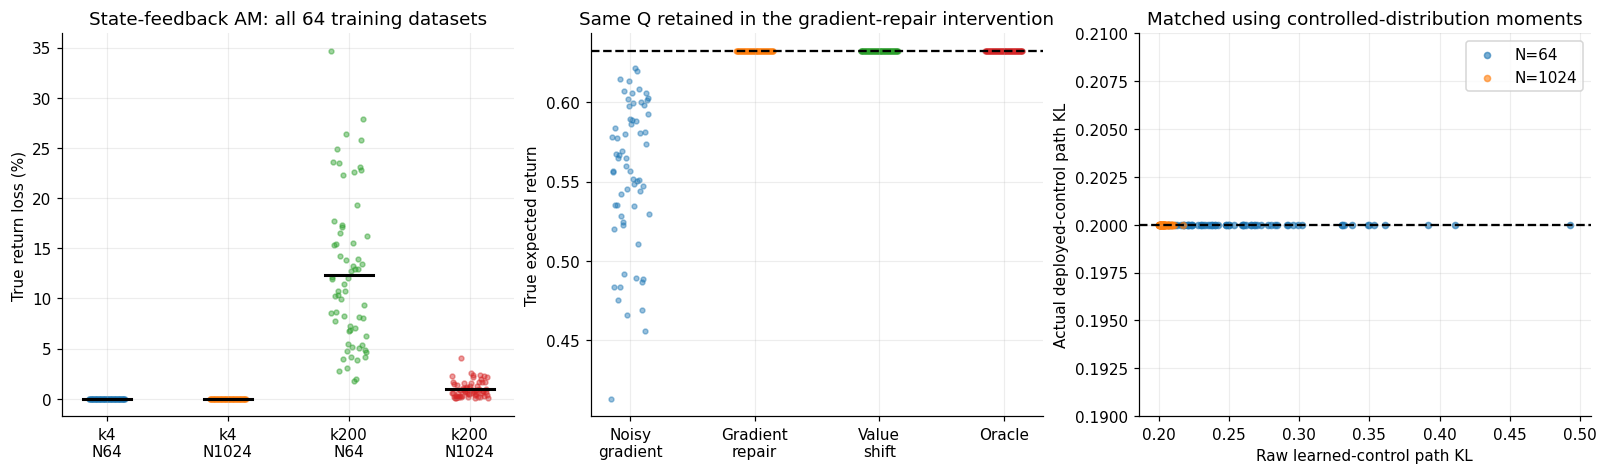

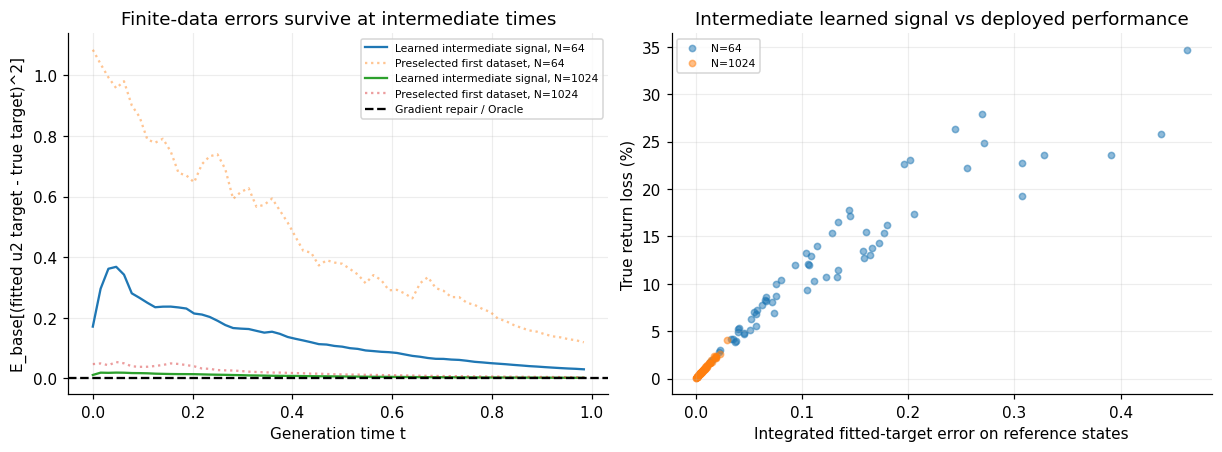

In [6]:
M=CFG['feedback_steps']; dt=1/M; a=A[1]; F=np.exp(a*dt); Bd=np.expm1(a*dt)/a; S=v(dt)
times=np.arange(M)*dt

def reference_paths(seed,n):
    rng=np.random.default_rng(seed+CFG['feedback_seed_offset'])
    paths=np.zeros((n,M+1))
    noise=rng.standard_normal((n,M))
    for j in range(M): paths[:,j+1]=F*paths[:,j]+np.sqrt(S)*noise[:,j]
    return paths

def fit_feedback(paths,k,repair=False):
    x=paths[:,:-1]; terminal=paths[:,-1]
    targets=BETA0*np.exp(a*(1-times))[None,:]*dg(terminal,k)[:,None]
    if repair: targets=np.zeros_like(targets)
    xm=x.mean(0); ym=targets.mean(0); xc=x-xm; yc=targets-ym
    denom=(xc*xc).sum(0)
    slopes=np.divide((xc*yc).sum(0),denom,out=np.zeros(M),where=denom>1e-14)
    intercepts=ym-slopes*xm
    residual=targets-(intercepts+slopes*x)
    return intercepts,slopes,float(np.mean(residual**2))

def feedback_moments(intercepts,slopes,scale):
    mu=0.; variance=0.; energy=0.
    for aa,bb in zip(intercepts,slopes):
        umean=scale*(aa+bb*mu); uvar=scale**2*bb**2*variance
        energy+=dt*((scale*BETA0)**2+umean**2+uvar)
        coeff=F+Bd*scale*bb
        mu=coeff*mu+Bd*scale*aa
        variance=coeff**2*variance+S
    return dict(true_return=scale*BETA0,actual_path_KL=.5*energy,terminal_x2_mean=mu,terminal_x2_var=variance)

feedback_rows=[]; credit_rows=[]; FB_MODELS={}
for seed in CFG['train_seeds']:
    allpaths=reference_paths(seed,max(CFG['feedback_sample_sizes']))
    for n in CFG['feedback_sample_sizes']:
        paths=allpaths[:n]
        for k in CFG['feedback_frequencies']:
            aa,bb,mse=fit_feedback(paths,k)
            raw=feedback_moments(aa,bb,1.)
            alpha=brentq(lambda scale:feedback_moments(aa,bb,scale)['actual_path_KL']-KL,0,1,xtol=1e-13)
            mom=feedback_moments(aa,bb,alpha)
            terminal_cos2=np.exp(-2*k*k*mom['terminal_x2_var'])*np.cos(2*k*mom['terminal_x2_mean'])
            deployment_q_rmse=EPS*np.sqrt((1-terminal_cos2)/2)
            deployment_g_rmse=EPS*k*np.sqrt((1+terminal_cos2)/2)
            FB_MODELS[(seed,k,n)]=(aa,bb,alpha)
            # These diagnostic expectations use the reference state distribution, not test trajectories.
            fitted_error=aa**2+bb**2*v(times)
            population_affine_mean=BETA0*np.exp(a*(1-times))*mean_g(k)
            fit_to_conditional=fitted_error-2*aa*population_affine_mean+BETA0**2*effective_energy(times,k)
            for j in range(M):
                credit_rows.append(dict(seed=seed,k=k,N=n,t=times[j],
                    fitted_target_error_vs_true=fitted_error[j],
                    fitted_target_error_vs_conditional=fit_to_conditional[j],
                    exact_conditional_target_error=BETA0**2*effective_energy(times[j],k),
                    raw_pathwise_target_error=BETA0**2*path_energy(times[j],k)))
            feedback_rows.append(dict(seed=seed,k=k,N=n,condition='Noisy gradient',scale=alpha,
                raw_KL=raw['actual_path_KL'],training_target_residual_MSE=mse,**mom,
                deployed_Q_RMSE=deployment_q_rmse,used_terminal_gradient_RMSE=deployment_g_rmse,
                scalar_critic_gradient_RMSE=deployment_g_rmse,
                intermediate_fitted_target_error_energy=dt*fitted_error.sum(),
                return_gap=J0-mom['true_return'],relative_gap=1-alpha))
            ra,rb,_=fit_feedback(paths,k,repair=True)
            # The scalar Q values are unchanged in repair; only terminal derivatives are replaced.
            check(f'feedback repair coefficients seed={seed} k={k} N={n}',np.max(np.abs(np.r_[ra,rb]))<1e-12)
            for condition in ['Gradient repair','Value shift','Oracle']:
                rm=feedback_moments(ra,rb,1.)
                feedback_rows.append(dict(seed=seed,k=k,N=n,condition=condition,scale=1.,
                    raw_KL=rm['actual_path_KL'],training_target_residual_MSE=0.,**rm,
                    deployed_Q_RMSE=np.sqrt(q_mse(k)) if condition!='Oracle' else 0.,
                    used_terminal_gradient_RMSE=0.,
                    scalar_critic_gradient_RMSE=np.sqrt(g_mse(k)) if condition=='Gradient repair' else 0.,
                    intermediate_fitted_target_error_energy=0.,return_gap=J0-rm['true_return'],relative_gap=0.))
FB=pd.DataFrame(feedback_rows); FB_SUM=summarize(FB,['condition','k','N'])
CREDIT=pd.DataFrame(credit_rows)
check('fitted versus conditional squared error nonnegative',CREDIT.fitted_target_error_vs_conditional.min()>-1e-12)
check('all feedback deployment KL budgets',np.max(np.abs(FB.actual_path_KL-KL))<1e-10)
check('value error remains small under deployed distribution',FB.deployed_Q_RMSE.max()<=EPS)
display(FB_SUM[FB_SUM.condition=='Noisy gradient'])
display(FB.groupby('condition').agg(min_KL=('actual_path_KL','min'),max_KL=('actual_path_KL','max'),
    min_raw_KL=('raw_KL','min'),max_raw_KL=('raw_KL','max'),max_deployed_Q_RMSE=('deployed_Q_RMSE','max')))

# Check the first selected model against an independent lstsq implementation.
paths=reference_paths(CFG['train_seeds'][0],max(CFG['feedback_sample_sizes']))[:64]
aa,bb,_=FB_MODELS[(CFG['train_seeds'][0],200.,64)]
for j in [1,16,32,63]:
    target=BETA0*np.exp(a*(1-times[j]))*dg(paths[:,-1],200.)
    fit=np.linalg.lstsq(np.column_stack([np.ones(len(paths)),paths[:,j]]),target,rcond=None)[0]
    check(f'independent state-feedback least squares j={j}',np.linalg.norm(fit-[aa[j],bb[j]])<1e-10)

fig,axes=plt.subplots(1,3,figsize=(14.5,4.2),constrained_layout=True)
for idx,(k,n) in enumerate([(4.,64),(4.,1024),(200.,64),(200.,1024)]):
    sub=FB[(FB.condition=='Noisy gradient')&(FB.k==k)&(FB.N==n)]
    offsets=np.linspace(-.15,.15,len(sub))
    axes[0].scatter(idx+offsets,100*sub.relative_gap,s=10,alpha=.45)
    axes[0].plot([idx-.2,idx+.2],[100*sub.relative_gap.mean()]*2,'k-',lw=2)
axes[0].set(xticks=range(4),xticklabels=['k4\nN64','k4\nN1024','k200\nN64','k200\nN1024'],
            ylabel='True return loss (%)',title='State-feedback AM: all 64 training datasets')
sub=FB[(FB.k==200.)&(FB.N==64)]
for idx,condition in enumerate(['Noisy gradient','Gradient repair','Value shift','Oracle']):
    data=sub[sub.condition==condition]
    axes[1].scatter(idx+np.linspace(-.15,.15,len(data)),data.true_return,s=10,alpha=.45)
axes[1].axhline(J0,color='black',ls='--')
axes[1].set(xticks=range(4),xticklabels=['Noisy\ngradient','Gradient\nrepair','Value\nshift','Oracle'],
            ylabel='True expected return',title='Same Q retained in the gradient-repair intervention')
for n in CFG['feedback_sample_sizes']:
    data=FB[(FB.condition=='Noisy gradient')&(FB.k==200.)&(FB.N==n)]
    axes[2].scatter(data.raw_KL,data.actual_path_KL,label=f'N={n}',alpha=.6,s=16)
axes[2].axhline(KL,color='black',ls='--')
axes[2].set(xlabel='Raw learned-control path KL',ylabel='Actual deployed-control path KL',
            title='Matched using controlled-distribution moments',ylim=(.19,.21))
axes[2].legend()
savefig(fig,'04_state_feedback_and_causal_controls')

fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for n in CFG['feedback_sample_sizes']:
    sub=CREDIT[(CREDIT.k==200.)&(CREDIT.N==n)]
    mean=sub.groupby('t').fitted_target_error_vs_true.mean()
    axes[0].plot(mean.index,mean.values,label=f'Learned intermediate signal, N={n}')
    selected=sub[sub.seed==CFG['train_seeds'][0]]
    axes[0].plot(selected.t,selected.fitted_target_error_vs_true,ls=':',alpha=.45,
                 label=f'Preselected first dataset, N={n}')
    data=FB[(FB.condition=='Noisy gradient')&(FB.k==200.)&(FB.N==n)]
    axes[1].scatter(data.intermediate_fitted_target_error_energy,100*data.relative_gap,
                    label=f'N={n}',alpha=.5,s=17)
axes[0].axhline(0,color='black',ls='--',label='Gradient repair / Oracle')
axes[0].set(xlabel='Generation time t',ylabel='E_base[(fitted u2 target - true target)^2]',
            title='Finite-data errors survive at intermediate times')
axes[1].set(xlabel='Integrated fitted-target error on reference states',ylabel='True return loss (%)',
            title='Intermediate learned signal vs deployed performance')
for ax in axes: ax.legend(fontsize=7)
savefig(fig,'06_learned_intermediate_credit')

In [7]:
def rollout_feedback(intercepts,slopes,scale,seed,n):
    rng=np.random.default_rng(seed); x=np.zeros((n,3)); xbase=np.zeros_like(x)
    costs=np.zeros(n); ff=np.exp(A*dt)
    bd=np.array([dt if abs(aj)<1e-14 else np.expm1(aj*dt)/aj for aj in A])
    sigma=np.sqrt([v(dt,aj) for aj in A])
    for j in range(M):
        u=np.zeros_like(x); u[:,0]=scale*BETA0
        u[:,1]=scale*(intercepts[j]+slopes[j]*x[:,1])
        costs+=.5*dt*np.sum(u*u,axis=1)
        noise=rng.standard_normal((n,3))*sigma
        x=ff*x+bd*u+noise; xbase=ff*xbase+noise
    paired=x[:,0]-xbase[:,0]
    return dict(return_MC=x[:,0].mean(),return_SE=x[:,0].std(ddof=1)/np.sqrt(n),
        paired_return=paired.mean(),paired_SE=paired.std(ddof=1)/np.sqrt(n),
        KL_MC=costs.mean(),KL_SE=costs.std(ddof=1)/np.sqrt(n),
        terminal_x2_mean_MC=x[:,1].mean(),terminal_x2_mean_SE=x[:,1].std(ddof=1)/np.sqrt(n))

roll_rows=[]
for k,n in [(4.,64),(200.,64),(200.,1024)]:
    aa,bb,alpha=FB_MODELS[(CFG['rollout_training_seed'],k,n)]
    exact=feedback_moments(aa,bb,alpha)
    for seed in CFG['rollout_seeds']:
        r=rollout_feedback(aa,bb,alpha,seed,CFG['rollout_paths'])
        roll_rows.append(dict(k=k,N=n,test_seed=seed,**r,exact_return=exact['true_return'],exact_KL=exact['actual_path_KL']))
        check(f'independent SDE paired return k={k} N={n} seed={seed}',abs(r['paired_return']-exact['true_return'])<1e-10)
        check(f'independent SDE absolute return k={k} N={n} seed={seed}',abs(r['return_MC']-exact['true_return'])<6*r['return_SE'])
        check(f'independent SDE controlled KL k={k} N={n} seed={seed}',abs(r['KL_MC']-KL)<6*r['KL_SE']+1e-10)
        check(f'independent SDE x2 moment k={k} N={n} seed={seed}',
              abs(r['terminal_x2_mean_MC']-exact['terminal_x2_mean'])<6*r['terminal_x2_mean_SE']+1e-10)
ROLLOUT=pd.DataFrame(roll_rows); display(ROLLOUT)
print('Paired return SE is numerically zero because x1 control is deterministic and noises are shared.')
print('This is an implementation check, NOT additional independent statistical evidence.')
print('Inference uses the 64 independent training datasets; test trajectories are not training replications.')

,k,N,test_seed,return_MC,return_SE,paired_return,paired_SE,KL_MC,KL_SE,terminal_x2_mean_MC,terminal_x2_mean_SE,exact_return,exact_KL
0,4.0,64,503001,0.633839,0.011004,0.632383,1.440166e-17,0.200001,5.685326e-07,0.016079,0.024506,0.632383,0.2
1,4.0,64,503002,0.650791,0.011198,0.632383,1.436271e-17,0.200000,5.718142e-07,-0.028107,0.024003,0.632383,0.2
2,4.0,64,503003,0.648002,0.011019,0.632383,1.472801e-17,0.200001,5.696416e-07,0.012723,0.024363,0.632383,0.2
3,4.0,64,503004,0.635145,0.010985,0.632383,1.439581e-17,0.200000,5.465058e-07,-0.062828,0.024250,0.632383,0.2
4,4.0,64,503005,0.654982,0.011011,0.632383,1.462049e-17,0.200000,5.497024e-07,-0.018550,0.024029,0.632383,0.2
5,200.0,64,503001,0.414517,0.011004,0.413061,1.013557e-17,0.200866,5.121890e-04,1.013238,0.026529,0.413061,0.2
6,200.0,64,503002,0.431469,0.011198,0.413061,1.099999e-17,0.199474,5.064446e-04,0.964437,0.025976,0.413061,0.2
7,200.0,64,503003,0.428680,0.011019,0.413061,1.064393e-17,0.200775,5.100613e-04,1.009200,0.026381,0.413061,0.2
8,200.0,64,503004,0.415823,0.010985,0.413061,9.986360e-18,0.199110,4.964041e-04,0.927697,0.026244,0.413061,0.2
9,200.0,64,503005,0.435660,0.011011,0.413061,1.116313e-17,0.199741,4.988276e-04,0.975011,0.026009,0.413061,0.2


Paired return SE is numerically zero because x1 control is deterministic and noises are shared.
This is an implementation check, NOT additional independent statistical evidence.
Inference uses the 64 independent training datasets; test trajectories are not training replications.


### B.6. 必须保留的反例：精确优化时，大梯度误差不必带来大性能损失

若 $|\widehat Q-Q|\le\epsilon$ **全局成立**，且 $u_Q^*,u_{\widehat Q}^*$ 分别精确优化同一个
KL 可行集上的真实/近似奖励，则直接由最优性可得
$$J_Q(u_Q^*)-J_Q(u_{\widehat Q}^*)\le2\epsilon.$$
证明：在两端各替换一次奖励最多损失 $\epsilon$，中间的近似奖励最优性项非正。
所以不可以声称“Q 全局几乎相同，但精确最优控制的真实收益能任意糟糕”。
有限样本 AM 回归不等于精确优化 $\mathbb E\widehat Q$；因此前面的有限样本损失可能大于 $2\epsilon$，
这不违反该界，而是表明**梯度驱动的有限数据更新误差**与**奖励函数本身的最优解偏差**不同。
仅在有限数据分布上 Q 的 MSE 小时，该全局界也不能直接套用。

对本例，还能算出全状态反馈策略类的精确最优路径分布：
$$\frac{dP_\beta^*}{dP^0}=\frac{\exp(\beta\widehat Q_k(X_T))}{Z(\beta)}.$$
终点 tilt 经 Doob 变换可由因果反馈控制实现；它的路径 KL 恰好等于该终点 tilt 的 KL，
**这是精确最优 benchmark 的特殊性质**，不能用于替换前面普通控制的 path-KL。
第一维与第二维在参考分布下独立，故
$$\log Z=\tfrac12\beta^2+\log Z_2(\beta),\quad
Z_2=\mathbb E_{X\sim N(0,V)}e^{\beta\epsilon\sin(kX)},$$
$$\mathrm{KL}=\tfrac12\beta^2+\beta\partial_\beta\log Z_2-\log Z_2=.2,
\qquad J_Q(P_\beta^*)=\beta.$$
求根得到 matched-KL 的 $\beta$。用收敛的 Fourier–Bessel 展开避免高频 Gaussian quadrature 混叠：
$$Z_2=I_0(\beta\epsilon)+2\sum_{m\ge1}(-1)^m I_{2m}(\beta\epsilon)e^{-2m^2k^2V}.$$
这给出理论最优 benchmark，**不是声称跑了一个收敛的 AM 神经网络**。

,k,beta,true_return,return_gap,relative_gap,actual_path_KL,global_gap_bound
0,1.0,0.63244,0.63244,0.000016,0.000025,0.2,0.02
1,4.0,0.63244,0.63244,0.000016,0.000025,0.2,0.02
2,16.0,0.63244,0.63244,0.000016,0.000025,0.2,0.02
3,64.0,0.63244,0.63244,0.000016,0.000025,0.2,0.02
4,200.0,0.63244,0.63244,0.000016,0.000025,0.2,0.02


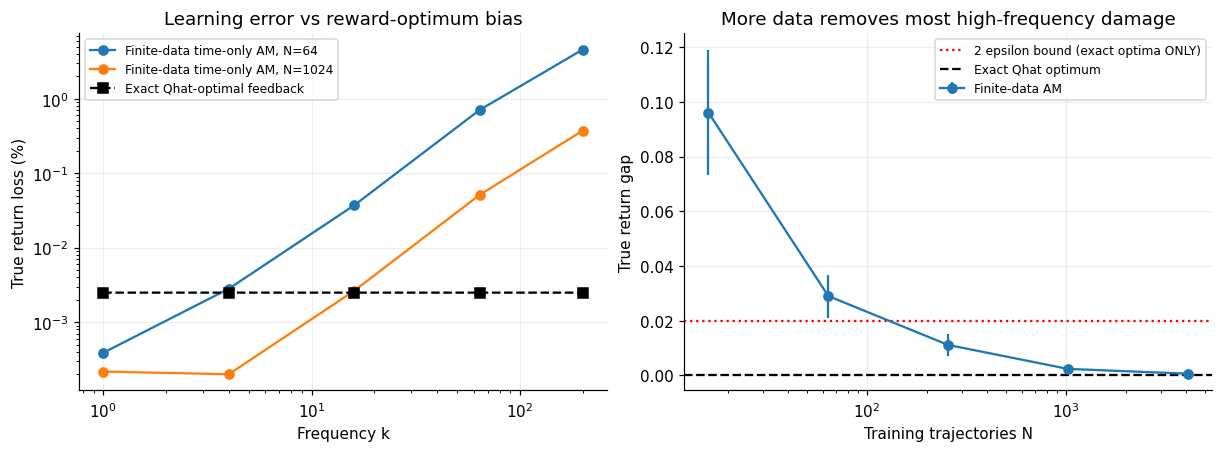

In [8]:
def z2_and_derivative(beta,k,terms=None):
    terms=CFG['bessel_terms'] if terms is None else terms
    z=beta*EPS; m=np.arange(1,terms+1); weights=2*(-1.)**m*np.exp(-2*m*m*k*k*V)
    return (iv(0,z)+np.sum(weights*iv(2*m,z)),
            EPS*(ivp(0,z)+np.sum(weights*ivp(2*m,z))))

def ideal_kl(beta,k):
    zz,dzz=z2_and_derivative(beta,k)
    return .5*beta*beta+beta*dzz/zz-np.log(zz)

ideal_rows=[]
for k in CFG['frequencies']:
    beta=brentq(lambda b:ideal_kl(b,k)-KL,0,2*BETA0,xtol=1e-14)
    zz,dzz=z2_and_derivative(beta,k)
    ideal_rows.append(dict(k=k,beta=beta,true_return=beta,return_gap=J0-beta,
        relative_gap=(J0-beta)/J0,actual_path_KL=ideal_kl(beta,k),global_gap_bound=2*EPS))
    zmore,dmore=z2_and_derivative(beta,k,2*CFG['bessel_terms'])
    check(f'Bessel truncation k={k}',max(abs(zmore-zz),abs(dmore-dzz))<1e-14)
    # Independent quadrature over wrapped-normal phase, with its own Fourier density.
    order=np.arange(1,80)
    def phase_density(theta):
        return (1+2*np.sum(np.exp(-.5*order**2*k*k*V)*np.cos(order*theta)))/(2*np.pi)
    zquad=quad(lambda th:np.exp(beta*EPS*np.sin(th))*phase_density(th),-np.pi,np.pi,epsabs=1e-12)[0]
    dquad=quad(lambda th:EPS*np.sin(th)*np.exp(beta*EPS*np.sin(th))*phase_density(th),-np.pi,np.pi,epsabs=1e-12)[0]
    check(f'independent phase quadrature k={k}',max(abs(zquad-zz),abs(dquad-dzz))<1e-11)
IDEAL=pd.DataFrame(ideal_rows)
check('ideal controls match KL',np.max(np.abs(IDEAL.actual_path_KL-KL))<1e-12)
check('ideal performance obeys uniform-value-error bound',np.all(IDEAL.return_gap<=2*EPS+1e-12))
display(IDEAL)

fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for n in [64,1024]:
    sub=ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.N==n)]
    axes[0].loglog(sub.k,100*sub.mean_relative_gap,'o-',label=f'Finite-data time-only AM, N={n}')
axes[0].loglog(IDEAL.k,100*IDEAL.relative_gap,'s--',color='black',label='Exact Qhat-optimal feedback')
axes[0].set(xlabel='Frequency k',ylabel='True return loss (%)',title='Learning error vs reward-optimum bias')
axes[0].legend(fontsize=8)
sub=ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.k==200.)]
axes[1].errorbar(sub.N,sub.mean_gap,yerr=sub.mean_gap_CI95_half,marker='o',label='Finite-data AM')
axes[1].axhline(2*EPS,color='red',ls=':',label='2 epsilon bound (exact optima ONLY)')
axes[1].axhline(IDEAL[IDEAL.k==200.].return_gap.iloc[0],color='black',ls='--',label='Exact Qhat optimum')
axes[1].set(xscale='log',xlabel='Training trajectories N',ylabel='True return gap',title='More data removes most high-frequency damage')
axes[1].legend(fontsize=8)
savefig(fig,'05_finite_learning_vs_exact_optimum')

### B.7. 如何解读结果，避免把受控现象写成普遍定理

- **可以验证**：value accuracy 不保证 gradient accuracy；终点误差经 Lean Adjoint 传播到 AM 中间目标；
  在本实验固定的有限数据、策略类和匹配 KL 流程中，它能导致真实性能下降；梯度修复可去除此下降。
- **重要限定**：逐轨迹误差不等于条件均值偏差。这里高频误差主要增加目标噪声，有限数据回归残留再影响控制。
  这支持“终点梯度可靠性会影响有限训练的信用信号质量与控制性能”，
  不支持“只要梯度误差大，充分优化后的性能必然显著下降”。
- **无算法主张**：未实现 ensemble、uncertainty estimator、自适应 trust region 或去噪方法；
  oracle gradient repair 是诊断干预，不是可部署的新方法。
- **外推边界**：构造的平滑振荡 critic、线性 Gaussian 系统、单次冻结轨迹 AM 回归、有限仿射反馈策略类；
  没有真实 critic 拟合，没有多轮 on-policy AM，也没有证明实际 c3/c4 的失败来自同一原因。
- **统计边界**：64 seeds 是轨迹训练数据的重复抽样，非 64 个独立 critic。
  误差条是均值的 pointwise 95% t 区间，不是多重比较校正后的全家族显著性，也不是实际 RL 的成功率区间。
- **识别边界**：原方向性实验隔离误差方向；本实验隔离 value accuracy 与 derivative accuracy。
  高频干预同时改变幅度、频谱和条件可预测性，因此不能由频率扫描单独声称某一个梯度标量普遍决定性能。
- **时空分辨率**：k=200 的理想条件信号集中在约 $1/k^2$ 的终点邻域，64 个时间区间的仿射控制不能表示它。
  这里没有声称该策略类逼近了近似 Q 的精确最优策略；参考轨迹与 sample-and-hold 转移则均是精确 Gaussian 转移，
  不是把 Euler 离散误差当作梯度问题。真实 Q 的最优常数控制在两种实验策略类中都可精确表示。
- **评价奖励不同**：有限 AM 控制在某些条件下的真实 Q 收益可以高于“近似 Q 的精确最优策略”，
  因为后者优化的是近似奖励，愿意为第二维的微小虚假奖励消耗预算；这不是矛盾。

In [9]:
high=VALUE[VALUE.k==200.].iloc[0]
er=ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.k==200.)&(ERM_SUM.N==64)].iloc[0]
erlarge=ERM_SUM[(ERM_SUM.condition=='Noisy gradient')&(ERM_SUM.k==200.)&(ERM_SUM.N==4096)].iloc[0]
fb=FB_SUM[(FB_SUM.condition=='Noisy gradient')&(FB_SUM.k==200.)&(FB_SUM.N==64)].iloc[0]
fblarge=FB_SUM[(FB_SUM.condition=='Noisy gradient')&(FB_SUM.k==200.)&(FB_SUM.N==1024)].iloc[0]
ideal=IDEAL[IDEAL.k==200.].iloc[0]
prop=PROP[PROP.k==200.].iloc[0]
outcomes=dict(
    value_close_gradient_inaccurate=bool(high.Q_RMSE_theory<.01 and high.grad_RMSE_theory>1),
    time_only_finite_sample_gap=bool(er.mean_gap>er.mean_gap_CI95_half),
    state_feedback_finite_sample_gap=bool(fb.mean_gap>fb.mean_gap_CI95_half),
    gradient_repair_recovers_oracle=bool(np.max(np.abs(FB[FB.condition=='Gradient repair'].return_gap))<1e-12),
    more_data_smaller_mean_gap=bool(erlarge.mean_gap<er.mean_gap and fblarge.mean_gap<fb.mean_gap),
    large_gradient_error_not_large_ideal_gap=bool(ideal.relative_gap<.001),
)
display(pd.Series(outcomes,name='Observed outcomes (not forced assertions)').to_frame())
display(Markdown(f'''
### 本次实际运行的结论

- k=200：全局 Q 误差 ≤ **{EPS}**，参考分布 Q RMSE **{high.Q_RMSE_theory:.6f}**，
  梯度 RMSE **{high.grad_RMSE_theory:.6f}**（真实梯度范数为 1）。
- 逐轨迹积分 adjoint 误差 **{prop.pathwise_integrated_adjoint_error:.6f}**，
  条件均值积分误差只有 **{prop.effective_integrated_adjoint_error:.8f}**。
  二者不能混为“有效信用分配误差”。
- 时间函数 AM，N=64，64 个训练数据 seeds：真实收益 **{er.mean_return:.6f}**，
  相对 Oracle 损失 **{100*er.mean_relative_gap:.3f}%**；
  损失百分比均值的 95% 区间为
  **[{100*(er.mean_gap-er.mean_gap_CI95_half)/J0:.3f}, {100*(er.mean_gap+er.mean_gap_CI95_half)/J0:.3f}]%**。
  N=4096 时平均损失 **{100*erlarge.mean_relative_gap:.3f}%**。
- 状态反馈 AM，N=64：真实收益 **{fb.mean_return:.6f}**，平均损失 **{100*fb.mean_relative_gap:.3f}%**；
  N=1024 时平均损失 **{100*fblarge.mean_relative_gap:.3f}%**。
  所有反馈控制校准后的实际 path-KL 最大偏差 **{np.max(np.abs(FB.actual_path_KL-KL)):.3g}**。
- 保留近似 Q 数值、只修复其训练中使用的梯度后，收益恢复 **{J0:.6f}**。
  相同参考 Q RMSE 的常数偏移对照也不损害控制。
- **反例必须保留**：同一个不可靠梯度 critic 的精确 Qhat 最优反馈策略，
  在同样 KL 下仅损失 **{100*ideal.relative_gap:.6f}%**。

**合适的 motivation 表述**：Q 值准确并不足以保证 AM 的终点梯度监督可靠。
终点梯度误差经伴随传播和有限样本回归后，可以污染中间控制更新并损害真实回报；
其影响取决于动力学、条件平均、策略类和采样预算，而非梯度误差大小单独决定。
本 notebook 对上述有限训练机制给出受控证据，不把它包装成真实 TRQAM 或一般 AM 的普遍结论。
'''))

TABLES=dict(value_and_gradient=VALUE,propagation=PROP,conditional_MC=CONDITIONAL,
    time_only_all_seeds=ERM,time_only_summary=ERM_SUM,state_feedback_all_seeds=FB,
    state_feedback_summary=FB_SUM,intermediate_learned_credit=CREDIT,
    independent_rollouts=ROLLOUT,exact_optimum=IDEAL)
for name,df in TABLES.items():
    (OUT/f'{name}.json').write_text(df.to_json(orient='table',indent=2))
keys=list(FB_MODELS)
np.savez_compressed(OUT/'all_state_feedback_models.npz',
    seed=np.array([k[0] for k in keys]),frequency=np.array([k[1] for k in keys]),N=np.array([k[2] for k in keys]),
    intercepts=np.stack([FB_MODELS[k][0] for k in keys]),slopes=np.stack([FB_MODELS[k][1] for k in keys]),
    scale=np.array([FB_MODELS[k][2] for k in keys]))
summary=dict(scalar_one_step=A_ROWS, scalar_config=dict(seed=17031,batch=_A_B,learning_rate=_A_ETA,repetitions=_A_REPS), config=CFG,config_sha256=CONFIG_SHA,versions=VERSIONS,outcomes=outcomes,
    k200=dict(value=high.to_dict(),propagation=prop.to_dict(),time_only_N64=er.to_dict(),
              time_only_N4096=erlarge.to_dict(),feedback_N64=fb.to_dict(),feedback_N1024=fblarge.to_dict(),
              exact_optimum=ideal.to_dict()),
    assertions=CHECKS,checks_passed=sum(c['passed'] for c in CHECKS),checks_total=len(CHECKS),
    feedback_models=len(FB_MODELS),time_only_experimental_conditions=len(ERM),execution_seconds=time.time()-START)
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False))
check_df=pd.DataFrame(CHECKS)
display(check_df.groupby('passed').size().rename('Numerical checks').to_frame())
assert check_df.passed.all()
print(f'Finished: {len(CHECKS)} numerical checks passed; {len(FB_MODELS)} feedback models retained; {time.time()-START:.1f}s CPU.')
print('All pre-specified conditions and training-data seeds retained. No seed selection.')
print('Outputs:', Path('runs') / OUT.name)

,Observed outcomes (not forced assertions)
value_close_gradient_inaccurate,True
time_only_finite_sample_gap,True
state_feedback_finite_sample_gap,True
gradient_repair_recovers_oracle,True
more_data_smaller_mean_gap,True
large_gradient_error_not_large_ideal_gap,True



### 本次实际运行的结论

- k=200：全局 Q 误差 ≤ **0.01**，参考分布 Q RMSE **0.007071**，
  梯度 RMSE **1.414214**（真实梯度范数为 1）。
- 逐轨迹积分 adjoint 误差 **9.587491**，
  条件均值积分误差只有 **0.00005000**。
  二者不能混为“有效信用分配误差”。
- 时间函数 AM，N=64，64 个训练数据 seeds：真实收益 **0.603426**，
  相对 Oracle 损失 **4.590%**；
  损失百分比均值的 95% 区间为
  **[3.346, 5.834]%**。
  N=4096 时平均损失 **0.097%**。
- 状态反馈 AM，N=64：真实收益 **0.554443**，平均损失 **12.335%**；
  N=1024 时平均损失 **0.967%**。
  所有反馈控制校准后的实际 path-KL 最大偏差 **1.05e-14**。
- 保留近似 Q 数值、只修复其训练中使用的梯度后，收益恢复 **0.632456**。
  相同参考 Q RMSE 的常数偏移对照也不损害控制。
- **反例必须保留**：同一个不可靠梯度 critic 的精确 Qhat 最优反馈策略，
  在同样 KL 下仅损失 **0.002500%**。

**合适的 motivation 表述**：Q 值准确并不足以保证 AM 的终点梯度监督可靠。
终点梯度误差经伴随传播和有限样本回归后，可以污染中间控制更新并损害真实回报；
其影响取决于动力学、条件平均、策略类和采样预算，而非梯度误差大小单独决定。
本 notebook 对上述有限训练机制给出受控证据，不把它包装成真实 TRQAM 或一般 AM 的普遍结论。


,Numerical checks
passed,
True,387


Finished: 387 numerical checks passed; 256 feedback models retained; 2.9s CPU.
All pre-specified conditions and training-data seeds retained. No seed selection.
Outputs: runs/01-motivation-atk82hn6
